# 30-day hospital readmission risk

**Tanner Allred · Houston**

This notebook is the walkthrough behind the recruiter README. It downloads the public UCI Diabetes 130-US hospitals extract (1999–2008), builds a discharge-time cohort, and ranks encounters by the risk of a readmission within 30 days.

The decision the score supports: a care-management team can enroll only a fraction of discharges. The pre-specified policy is the highest-risk 10%. Dollar results use planning assumptions (readmission cost, bundle cost, and a relative reduction). They are not an effect estimated from this file.

The implementation lives in `src/readmission/`. This notebook calls that package and shows the measured output.


## Setup

The raw CSV is about 19 MB and is gitignored. `download_dataset` checks the zip against a pinned SHA-256 before it is used.


In [1]:
from pathlib import Path
import os
import sys

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / "src" / "readmission").exists() and (ROOT.parent / "src" / "readmission").exists():
    os.chdir(ROOT.parent)
    ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from readmission.config import (
    INTERVENTION_COST_USD,
    PRIMARY_TARGET_FRACTION,
    READMISSION_COST_USD,
    RELATIVE_RISK_REDUCTION,
)
from readmission.pipeline import run_pipeline

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
print("Project root:", ROOT)
print(
    f"Assumptions locked before the test read: "
    f"readmission ${READMISSION_COST_USD:,.0f}, "
    f"bundle ${INTERVENTION_COST_USD:,.0f}, "
    f"relative reduction {RELATIVE_RISK_REDUCTION:.0%}, "
    f"panel {PRIMARY_TARGET_FRACTION:.0%}."
)


Project root: /workspace
Assumptions locked before the test read: readmission $16,000, bundle $500, relative reduction 20%, panel 10%.


## Cohort, split, and models

Encounters discharged expired, to hospice, or still in hospital are removed, along with three rows of unknown sex. Weight and payer code are dropped because they are missing too often to use. Race and sex are kept for the audit and left out of the design matrix.

Patients are split 60% fit / 20% calibration / 20% test. Isotonic calibration is fit on the calibration patients. Cross-validation refits the encoders inside each fold. The test patients are scored once.


In [2]:
payload = run_pipeline(save=True)
metrics = payload["metrics"]
cohort_log = metrics["cohort"]
split = metrics["split"]
print(
    f"Cohort {cohort_log['encounters']:,} encounters, "
    f"{cohort_log['patients']:,} patients, "
    f"30-day rate {cohort_log['readmission_rate']:.1%}."
)
print(
    f"Held out {split['test']['patients']:,} patients "
    f"({split['test']['encounters']:,} encounters), "
    f"prevalence {split['test']['prevalence']:.1%}."
)


Loading the UCI diabetes extract...


Cohort 99,337 encounters / 69,985 patients; test prevalence 0.112.


Cross-validating on development patients...


OOF AUC  logistic 0.663  gradient boosting 0.672


Fitting the final models and calibrating probabilities...


Scoring outreach policies and SHAP...


Wrote /workspace/reports/metrics.json


Cohort 99,337 encounters, 69,985 patients, 30-day rate 11.4%.
Held out 13,997 patients (19,894 encounters), prevalence 11.2%.


In [3]:
rows = []
for name in ("fit", "calib", "test"):
    part = split[name]
    rows.append(
        {
            "split": name,
            "encounters": part["encounters"],
            "patients": part["patients"],
            "readmissions_30d": part["readmissions_30d"],
            "prevalence": part["prevalence"],
        }
    )
display(pd.DataFrame(rows))


,split,encounters,patients,readmissions_30d,prevalence
0,fit,59639,41991,6800,0.114019
1,calib,19804,13997,2285,0.115381
2,test,19894,13997,2227,0.111943


## SQL cohort description

`sql/cohort_queries.sql` is executed in DuckDB against the cleaned encounter table. These tables describe the full analysis cohort. The model metrics above and below are computed on held-out patients only.


In [4]:
sql = payload["sql"]
print("Overview")
display(sql["cohort_overview"])
print("Prior inpatient stays")
display(sql["readmission_by_prior_inpatient"])
print("Any prior inpatient stay versus none")
display(sql["high_utilizer_gap"])
print("Primary diagnosis group")
display(sql["readmission_by_primary_diagnosis"])
print("Age band")
display(sql["readmission_by_age"])
print("HbA1c")
display(sql["readmission_by_a1c"])


Overview


,encounters,patients,readmissions_30d,readmission_rate,avg_length_of_stay_days,avg_prior_inpatient_stays
0,99337,69985,11312.0,0.1139,4.38,0.63


Prior inpatient stays


,prior_inpatient_stays,encounters,readmissions_30d,readmission_rate
0,0,66240,5689.0,0.0859
1,1,18983,2515.0,0.1325
2,2,7300,1309.0,0.1793
3,3,3271,688.0,0.2103
4,4+,3543,1111.0,0.3136


Any prior inpatient stay versus none


,utilizer,encounters,readmissions_30d,readmission_rate
0,No prior inpatient stay,66240,5689.0,0.0859
1,One or more prior inpatient stays,33097,5623.0,0.1699


... (2 outputs left out)

Age band


,age,encounters,readmissions_30d,readmission_rate
0,[0-10),160,3.0,0.0187
1,[10-20),690,40.0,0.0580
2,[20-30),1649,236.0,0.1431
3,[30-40),3764,424.0,0.1126
4,[40-50),9607,1024.0,0.1066
5,[50-60),17060,1667.0,0.0977
6,[60-70),22058,2493.0,0.1130
7,[70-80),25327,3052.0,0.1205
8,[80-90),16434,2065.0,0.1257
9,[90-100),2588,308.0,0.1190


HbA1c


,a1c_result,encounters,readmissions_30d,readmission_rate
0,NotMeasured,82503,9639.0,0.1168
1,Above8,8137,809.0,0.0994
2,Normal,4922,481.0,0.0977
3,Above7,3775,383.0,0.1015


## Charts for the cohort

The prior-year inpatient count is the sharp descriptive gradient. Age peaks in the 20s and rises again after 60. HbA1c blanks mean the test was not recorded; stays with a result have a slightly lower raw rate.


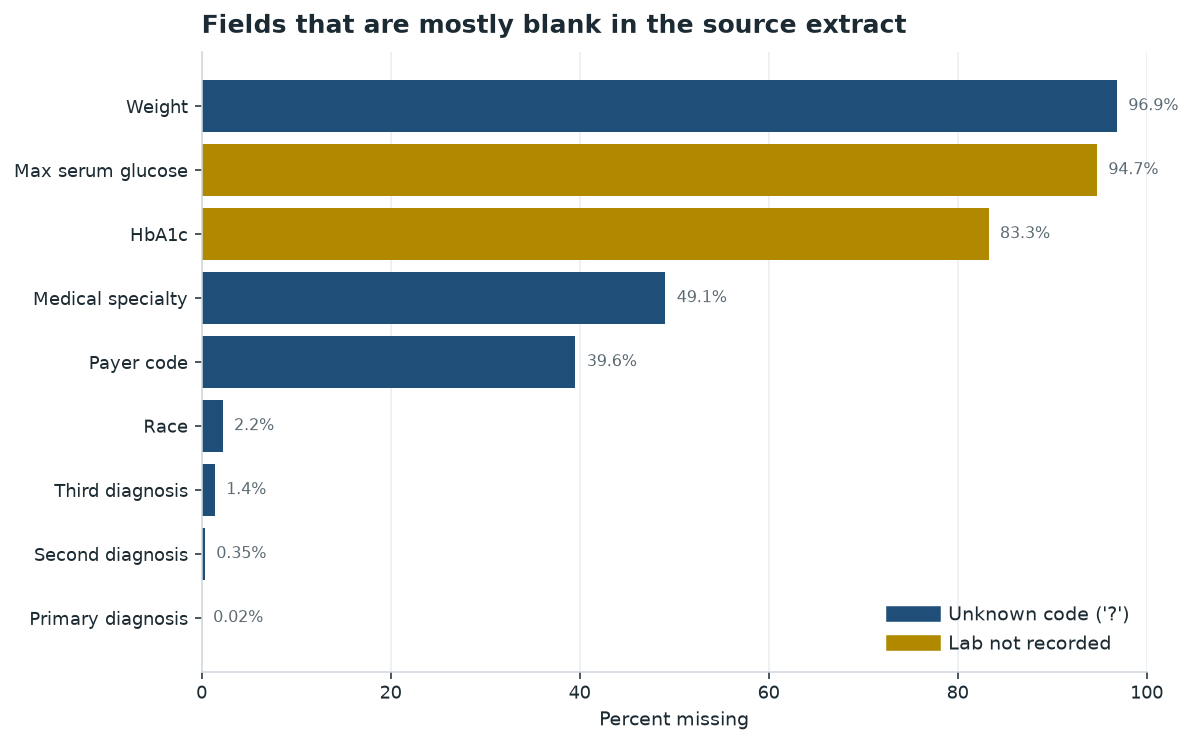

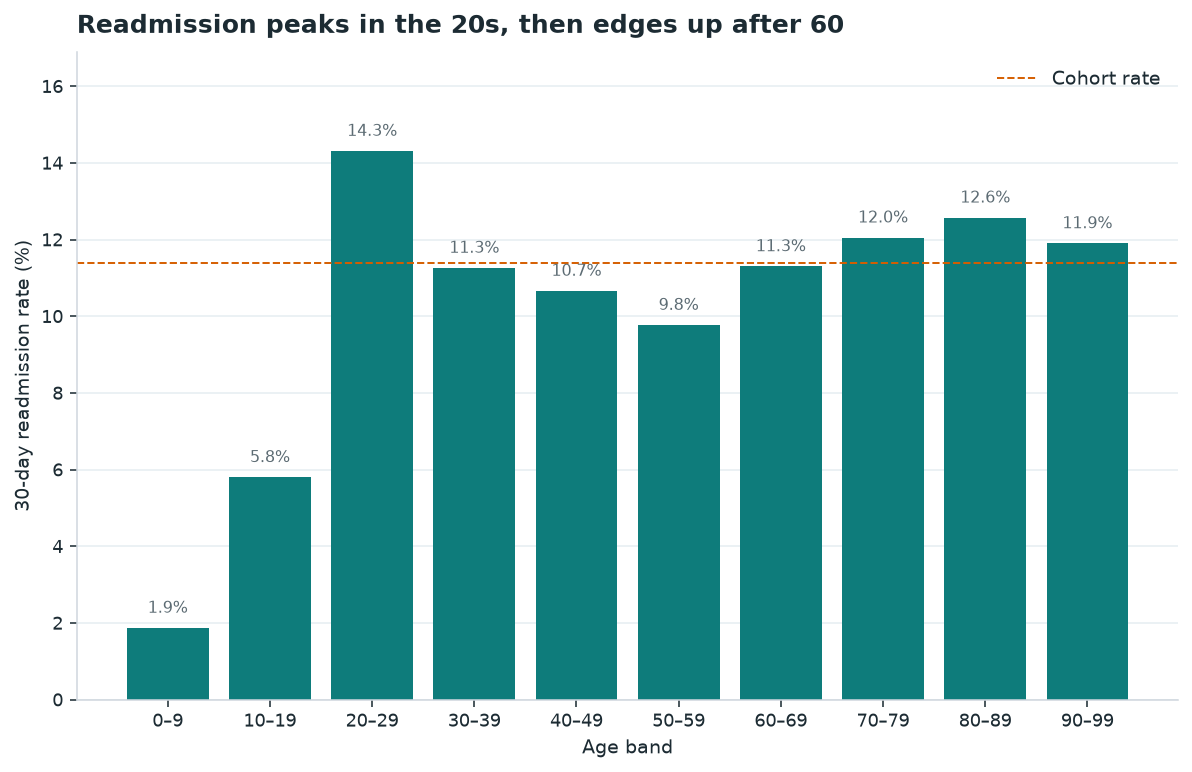

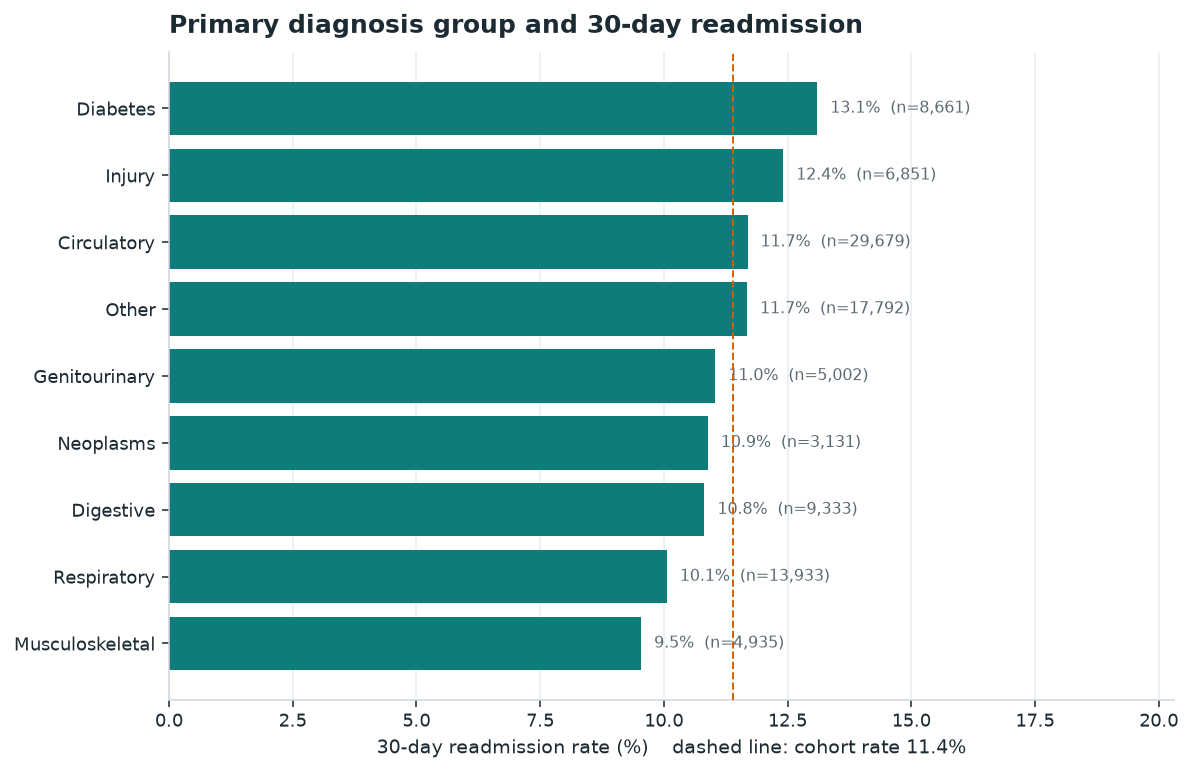

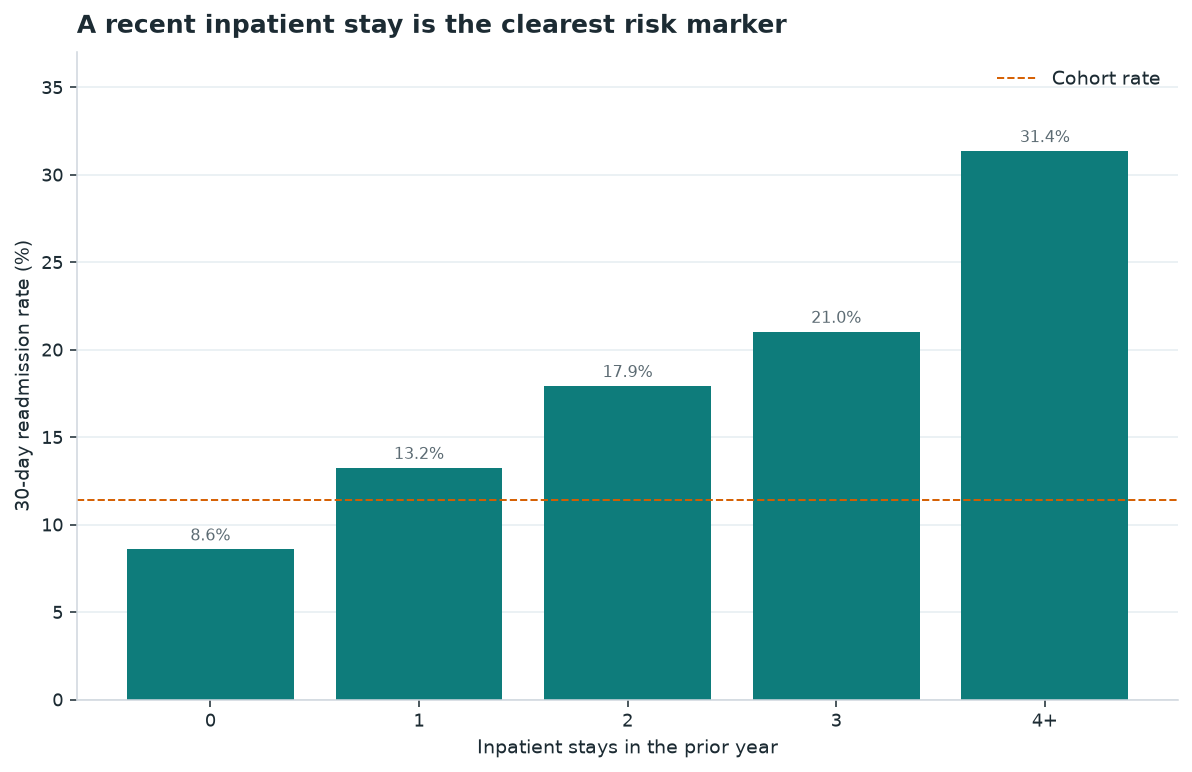

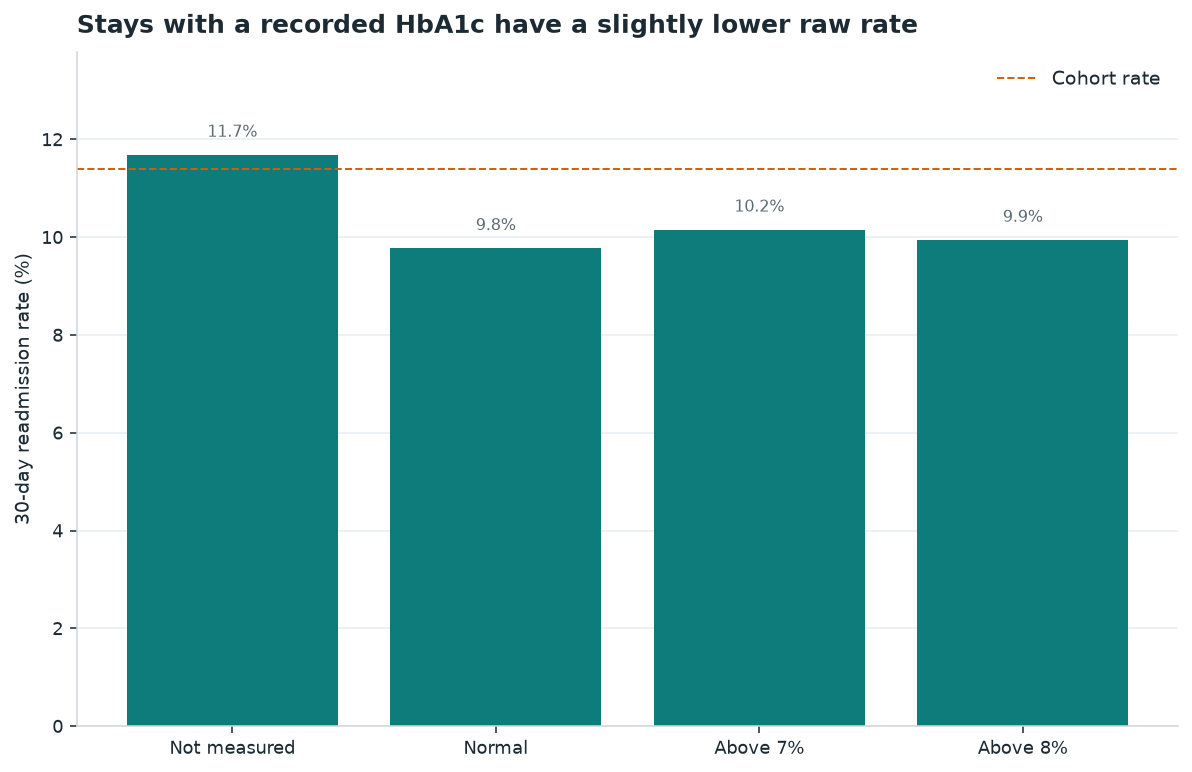

In [5]:
for name in (
    "01_missingness.png",
    "02_readmission_by_age.png",
    "03_readmission_by_diagnosis.png",
    "04_prior_inpatient.png",
    "05_a1c.png",
):
    display(Image(filename=str(ROOT / "reports" / "figures" / name), width=760))


## Discrimination, precision, and calibration

Average precision is the right companion to AUC when roughly one encounter in nine is positive. The reliability chart compares the class-weighted raw score with the isotonic probabilities. Ranking for the panel uses the raw score so that tied calibrated bins do not reshuffle the margin of the list.


In [6]:
test = metrics["test"]
cv = metrics["validation"]
summary = pd.DataFrame(
    [
        {
            "model": "Prior inpatient stays",
            "test_auc": test["prior_inpatient_auc"],
            "auc_ci95_low": None,
            "auc_ci95_high": None,
            "average_precision": None,
            "brier_calibrated": None,
            "ece_calibrated": None,
            "oof_auc": None,
        },
        {
            "model": "Logistic regression",
            "test_auc": test["logistic_regression"]["roc_auc"],
            "auc_ci95_low": test["logistic_regression"]["auc_ci95_low"],
            "auc_ci95_high": test["logistic_regression"]["auc_ci95_high"],
            "average_precision": test["logistic_regression"]["pr_auc"],
            "brier_calibrated": test["logistic_regression"]["brier_calibrated"],
            "ece_calibrated": test["logistic_regression"]["ece_calibrated"],
            "oof_auc": cv["logistic_regression"]["oof_auc"],
        },
        {
            "model": "Gradient boosting",
            "test_auc": test["gradient_boosting"]["roc_auc"],
            "auc_ci95_low": test["gradient_boosting"]["auc_ci95_low"],
            "auc_ci95_high": test["gradient_boosting"]["auc_ci95_high"],
            "average_precision": test["gradient_boosting"]["pr_auc"],
            "brier_calibrated": test["gradient_boosting"]["brier_calibrated"],
            "ece_calibrated": test["gradient_boosting"]["ece_calibrated"],
            "oof_auc": cv["gradient_boosting"]["oof_auc"],
        },
    ]
)
display(summary.round(3))
print(
    "Gradient boosting fold AUCs:",
    ", ".join(f"{value:.3f}" for value in cv["gradient_boosting"]["fold_auc"]),
)


,model,test_auc,auc_ci95_low,auc_ci95_high,average_precision,brier_calibrated,ece_calibrated,oof_auc
0,Prior inpatient stays,0.600,NaN,NaN,NaN,NaN,NaN,NaN
1,Logistic regression,0.652,0.639,0.664,0.201,0.096,0.009,0.663
2,Gradient boosting,0.664,0.651,0.678,0.218,0.095,0.006,0.672


Gradient boosting fold AUCs: 0.669, 0.672, 0.671, 0.672, 0.676


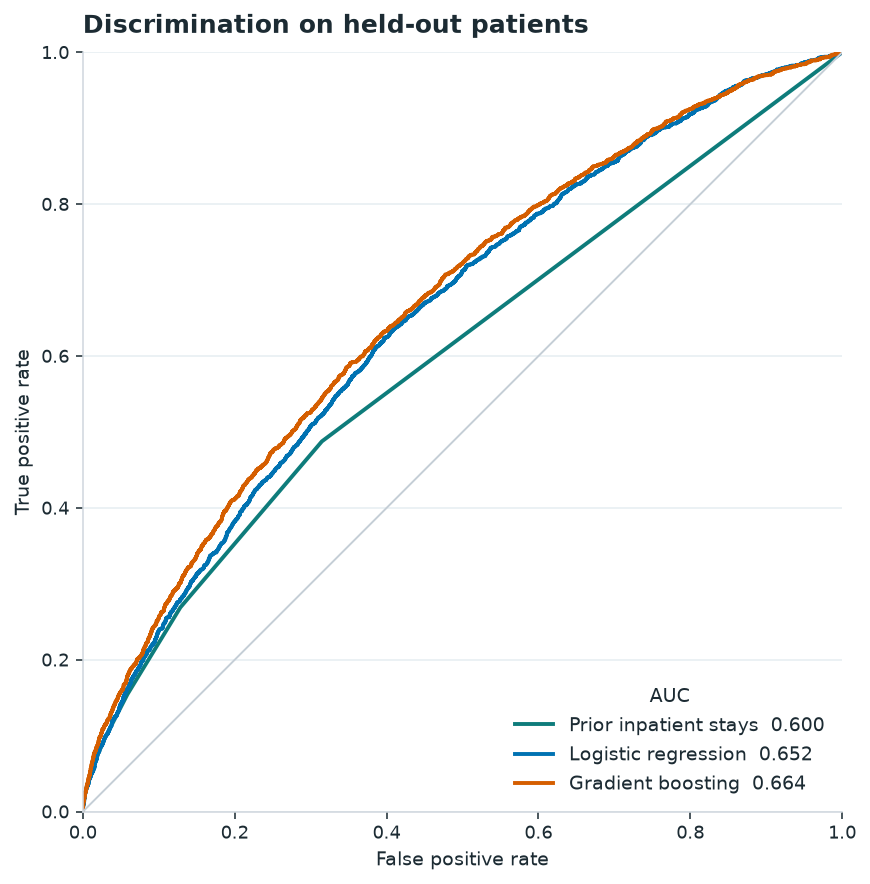

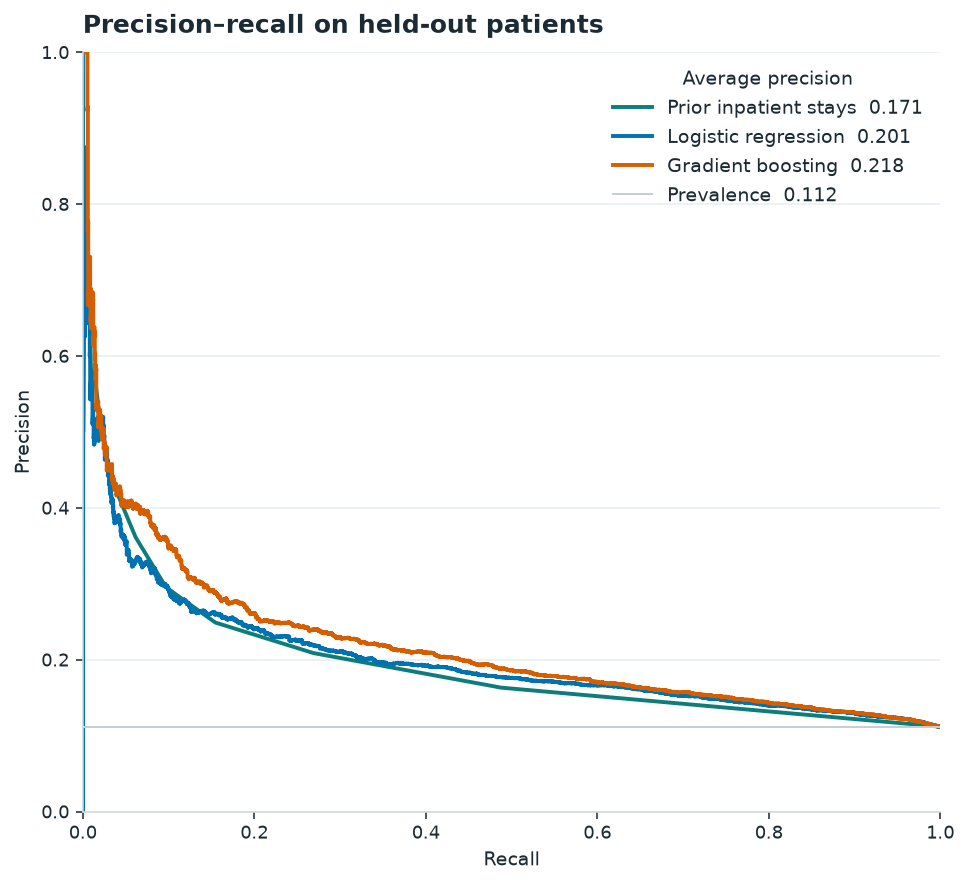

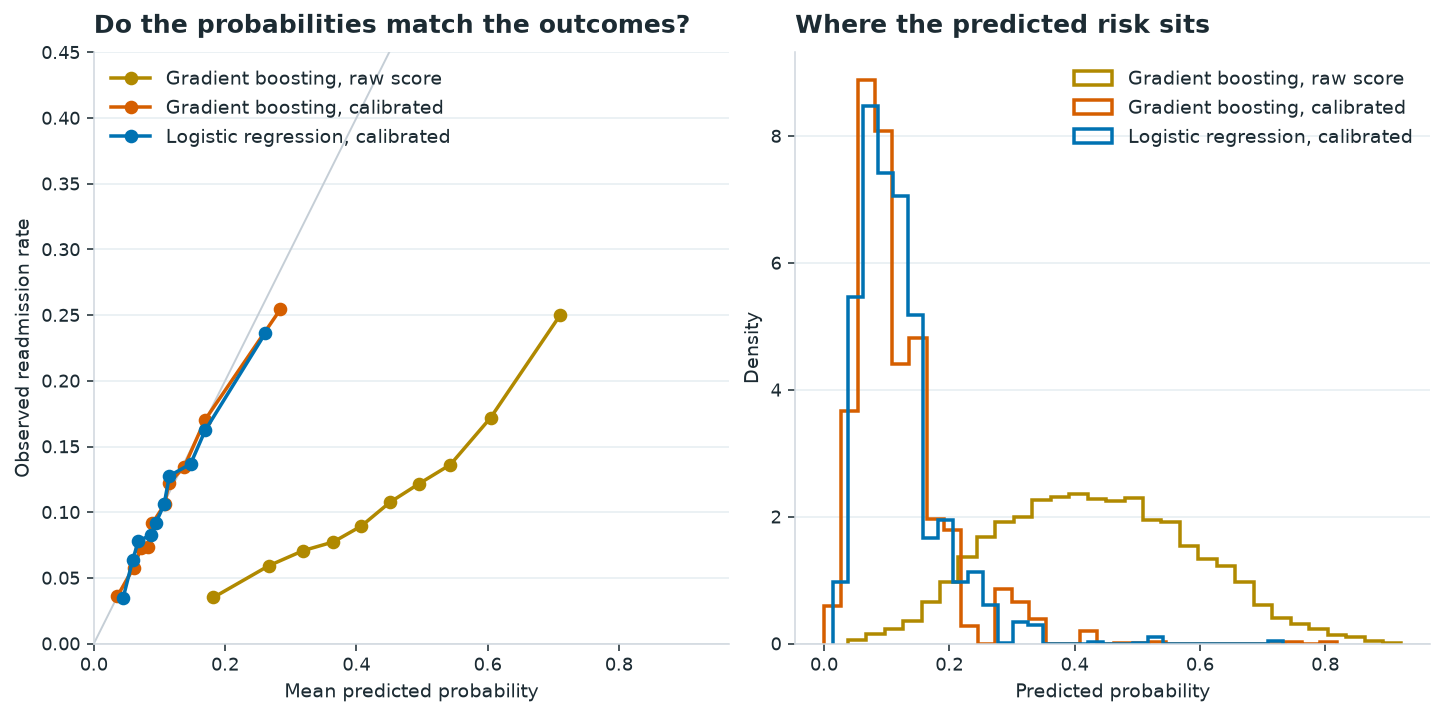

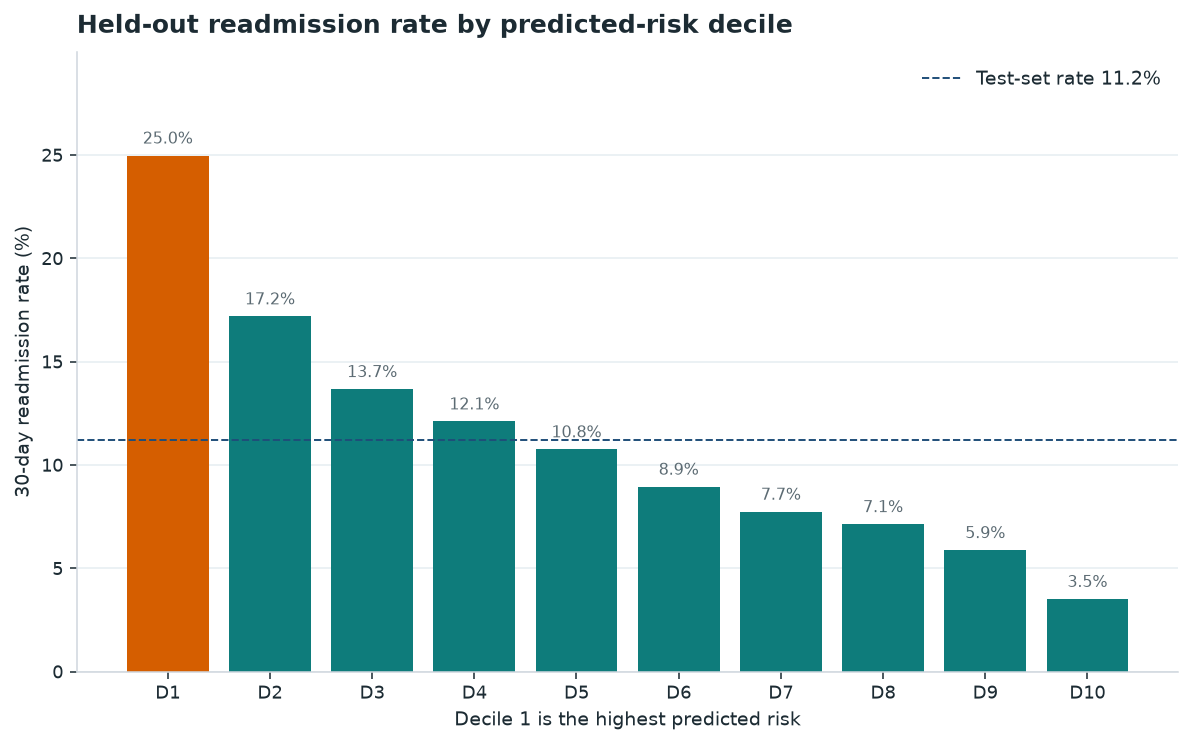

,risk_decile,n,readmissions,readmission_rate,lift,share_of_readmissions,mean_score
0,1,1990,497,0.250,2.231,0.223,0.710
1,2,1989,342,0.172,1.536,0.154,0.604
2,3,1989,272,0.137,1.222,0.122,0.543
3,4,1990,241,0.121,1.082,0.108,0.495
4,5,1989,214,0.108,0.961,0.096,0.451
5,6,1989,178,0.089,0.799,0.080,0.407
6,7,1990,154,0.077,0.691,0.069,0.365
7,8,1989,142,0.071,0.638,0.064,0.319
8,9,1989,117,0.059,0.525,0.053,0.267
9,10,1990,70,0.035,0.314,0.031,0.182


In [7]:
for name in (
    "06_roc.png",
    "07_precision_recall.png",
    "08_calibration.png",
    "09_risk_deciles.png",
):
    display(Image(filename=str(ROOT / "reports" / "figures" / name), width=760))
display(payload["deciles"].round(3))


## Interpretability

Mean absolute SHAP on a seeded sample of the test matrix. Orange bars are features whose higher values push the score toward readmission. Blue bars push the other way. Discharge home and a higher diabetes-medication count land on the blue side in this fit; that is an association in the score, not a reason to change a discharge plan.


,feature,mean_abs_shap,direction
0,number_inpatient,0.3182,1
1,discharge_group_Home,0.1602,-1
2,number_diagnoses,0.0761,1
3,age_mid,0.0705,1
4,time_in_hospital,0.0679,1
5,discharge_group_Transfer,0.0640,1
6,num_lab_procedures,0.0606,1
7,n_diabetes_meds,0.0553,-1
8,num_medications,0.0514,1
9,diag_1_group_Circulatory,0.0463,1


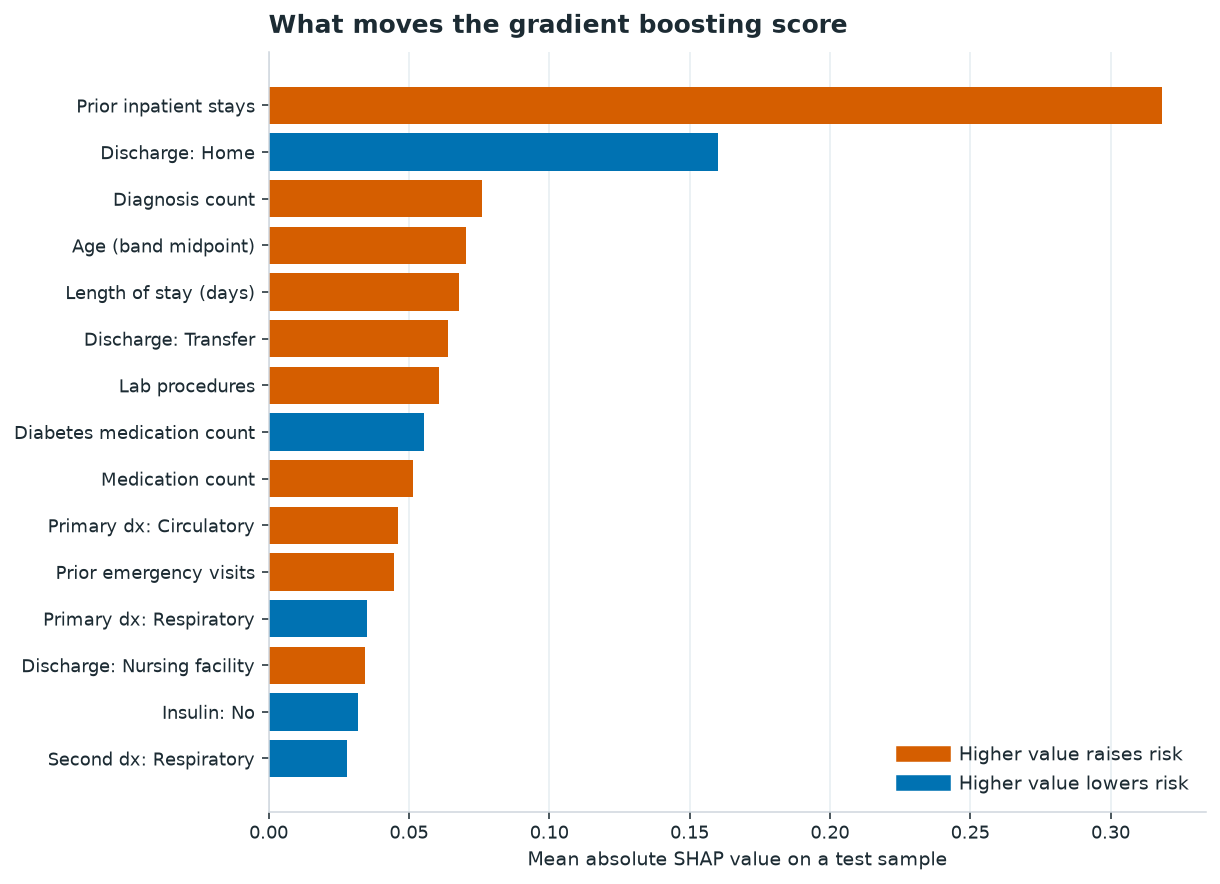

In [8]:
display(payload["importance"].head(12).round(4))
display(Image(filename=str(ROOT / "reports" / "figures" / "10_shap.png"), width=760))


## Cost of the top 10% panel

Net savings = (observed readmissions in the panel × relative reduction × readmission cost) − (panel size × bundle cost). The same formula is in the Calculator sheet of `reports/business_case.xlsx`, pointed at the three green input cells.

The random row uses the expected count at the base rate, so it does not depend on one unlucky draw. The 15% row later in the metrics file is the capacity that maximized net savings on the calibration patients.


,policy,n_targeted,observed_readmissions,precision,recall,readmissions_prevented,net_savings_usd,net_savings_per_1000_discharges_usd,break_even_intervention_cost_usd
0,random,1989,222.655,0.112,0.100,44.531,-282003.287,-14175.293,358.219
1,prior_inpatient,1989,443.000,0.223,0.199,88.600,423100.000,21267.719,712.720
2,logistic_regression,1989,471.000,0.237,0.211,94.200,512700.000,25771.589,757.768
3,gradient_boosting,1989,497.000,0.250,0.223,99.400,595900.000,29953.755,799.598


Capacity chosen on the calibration set: 15%. Test-set precision 22.9%, recall 30.6%, net per 1,000 discharges $34,704.


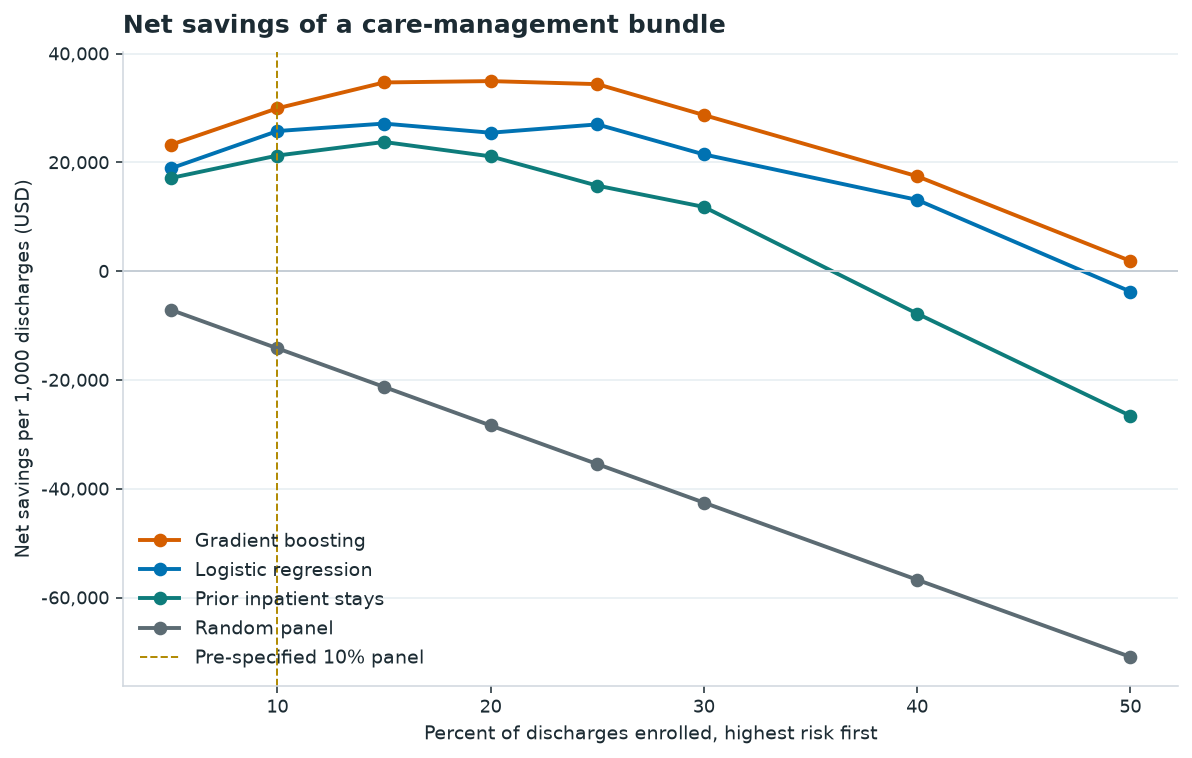

In [9]:
point = metrics["operating_point"]["policies"]
order = ["random", "prior_inpatient", "logistic_regression", "gradient_boosting"]
table = pd.DataFrame([{"policy": name, **point[name]} for name in order])
columns = [
    "policy",
    "n_targeted",
    "observed_readmissions",
    "precision",
    "recall",
    "readmissions_prevented",
    "net_savings_usd",
    "net_savings_per_1000_discharges_usd",
    "break_even_intervention_cost_usd",
]
display(table[columns].round(3))
chosen = metrics["calibration_chosen_fraction"]
chosen_test = metrics["calibration_chosen_test"]
print(
    f"Capacity chosen on the calibration set: {chosen:.0%}. "
    f"Test-set precision {chosen_test['precision']:.1%}, "
    f"recall {chosen_test['recall']:.1%}, "
    f"net per 1,000 discharges ${chosen_test['net_savings_per_1000_discharges_usd']:,.0f}."
)
display(Image(filename=str(ROOT / "reports" / "figures" / "11_net_savings.png"), width=760))


## Who the panel reaches, and how the file is handled

Recall here is the share of that group's readmissions that fell inside the global top 10%. Race and sex were not model features. Age was. Groups under 150 test encounters are flagged `small_sample` and should not be read as a disparity estimate.

The source file was de-identified before UCI published it (no names, addresses, exact dates, or medical-record numbers; age in bands). This notebook does not try to re-identify anyone. Outputs written to `reports/` are aggregates.


,group_type,group,n,prevalence,selection_rate,recall,precision,small_sample
0,age,70–79,4956,0.120,0.103,0.189,0.220,False
1,age,60–69,4480,0.112,0.103,0.235,0.255,False
2,age,80 and older,3901,0.121,0.094,0.188,0.243,False
3,age,50–59,3390,0.095,0.078,0.220,0.268,False
4,age,40–49,1882,0.102,0.104,0.240,0.235,False
5,age,Under 40,1285,0.112,0.147,0.424,0.323,False
6,gender,Female,10946,0.109,0.102,0.222,0.239,False
7,gender,Male,8948,0.115,0.098,0.224,0.264,False
8,race,Caucasian,14910,0.115,0.097,0.217,0.256,False
9,race,African American,3688,0.109,0.114,0.247,0.235,False


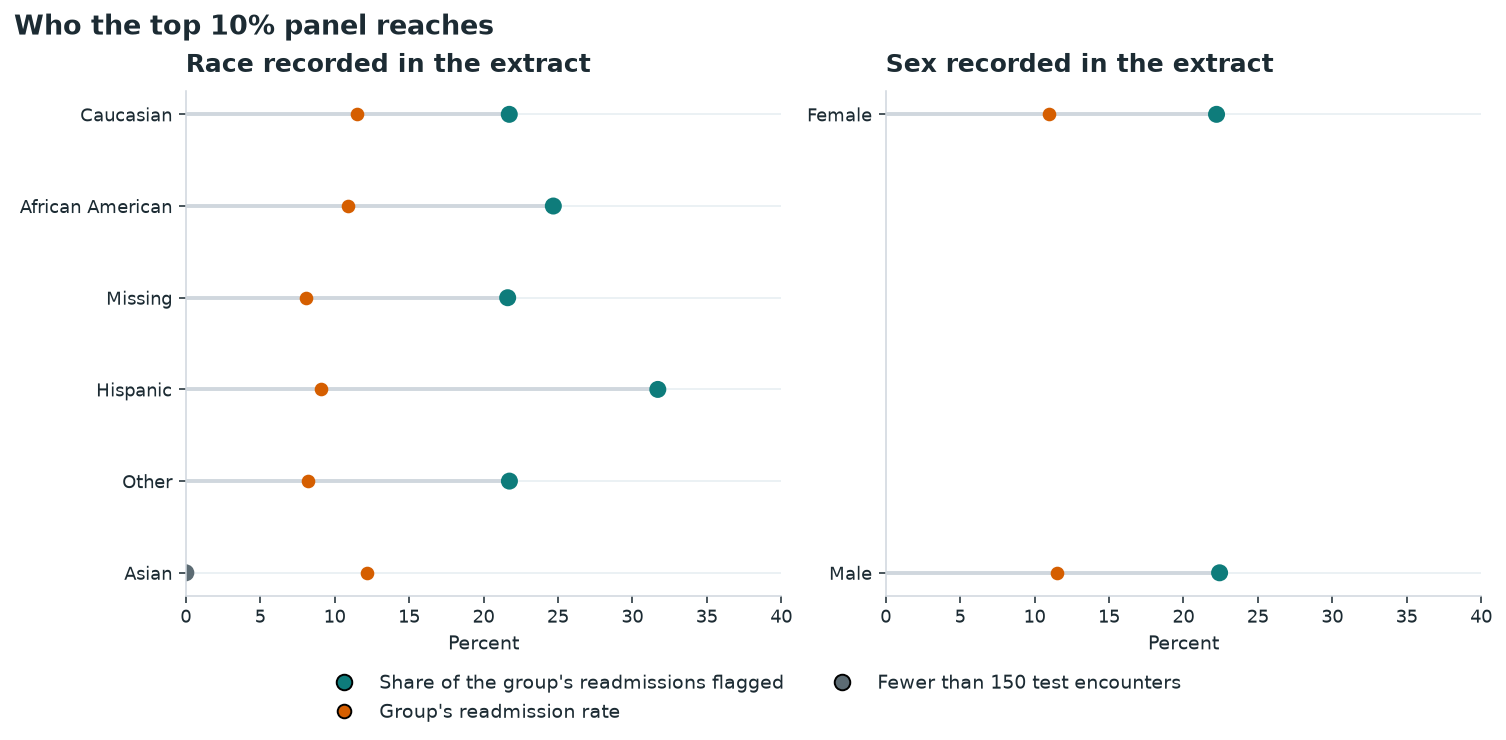

race: recall gap 10.0% (Hispanic 31.7% vs Caucasian 21.7%), 4 groups compared.
gender: recall gap 0.2% (Male 22.4% vs Female 22.2%), 2 groups compared.
age: recall gap 23.5% (Under 40 42.4% vs 80 and older 18.8%), 6 groups compared.


In [10]:
audit = payload["audit"].copy()
show_cols = [
    "group_type",
    "group",
    "n",
    "prevalence",
    "selection_rate",
    "recall",
    "precision",
    "small_sample",
]
display(audit[show_cols].round(3))
display(Image(filename=str(ROOT / "reports" / "figures" / "12_fairness.png"), width=820))
for kind, gap in metrics["fairness"]["gaps"].items():
    print(
        f"{kind}: recall gap {gap['gap']:.1%} "
        f"({gap['highest_group']} {gap['highest_recall']:.1%} vs "
        f"{gap['lowest_group']} {gap['lowest_recall']:.1%}), "
        f"{gap['groups_compared']} groups compared."
    )


## Limits worth keeping next to the result

- Encounters are from 1999–2008 and use ICD-9. Practice and payment policy have changed.
- The public file has no dates, so this is a patient holdout rather than a next-year test.
- An AUC of about 0.66 is enough to order a panel and too weak to label an individual patient.
- The 20% relative reduction is an assumption, applied evenly from the top of the list to the bottom.
- Specialty is missing about half the time, and the file has no hospital identifier.

Re-running this notebook overwrites `reports/` and should reproduce the README figures when the pinned data file and the seeds in `src/readmission/config.py` are unchanged.
